c:\Users\ASUS\anaconda3\envs\dsm_env\lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: driver CSV does not support open option GEOM
  return ogr_read(


Number of records for Algeria: 295
    pH water topsoil  pH water subsoil  pH water
7               5.86             5.390    5.6250
9               5.92             6.020    5.9700
10              6.27             5.750    6.0100
13              7.86             8.030    7.9450
15              7.32             7.490    7.4050
16              7.86             8.030    7.9450
17              6.94             7.280    7.1100
18              6.82             7.200    7.0100
19              7.14             7.550    7.3450
22              7.08             7.345    7.2125

Data types:
pH water topsoil    float64
pH water subsoil    float64
pH water            float64
dtype: object
Geometry conversion completed!
Polygon    295
Name: count, dtype: int64
CRS: EPSG:4326
Number of geometries: 295


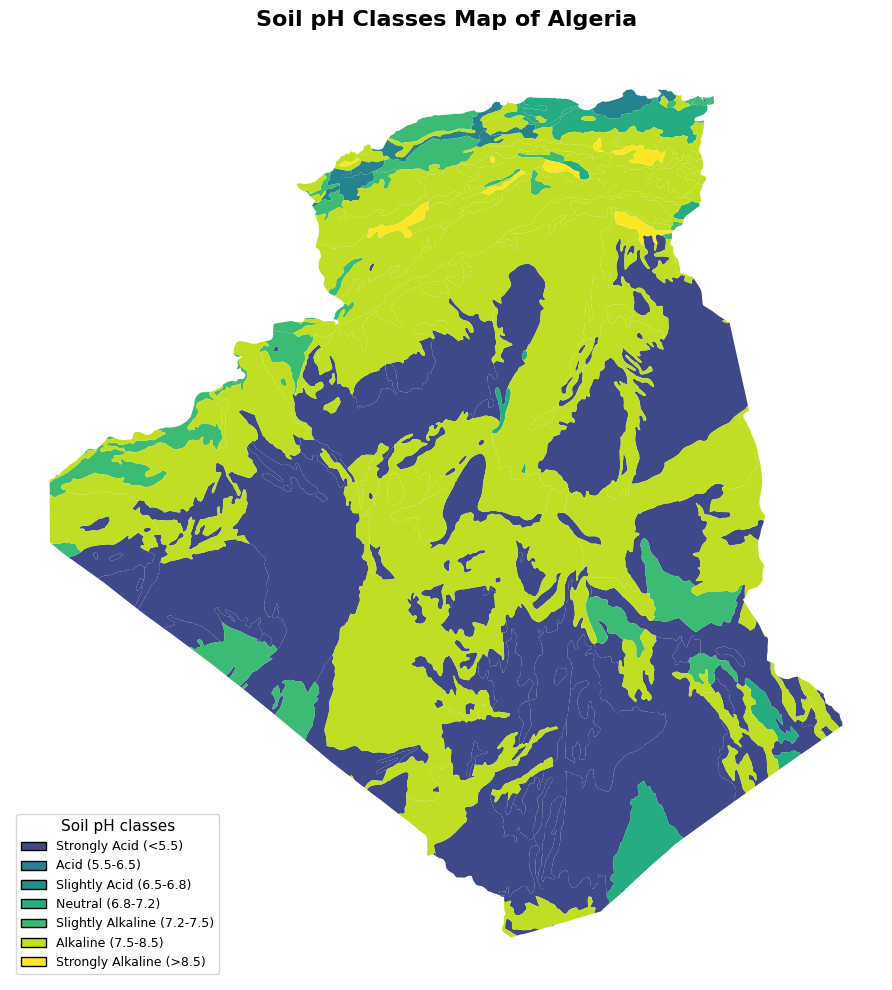


Number of records per pH class:
pH class
Strongly Acid (<5.5)           107
Acid (5.5-6.5)                  10
Slightly Acid (6.5-6.8)          0
Neutral (6.8-7.2)               14
Slightly Alkaline (7.2-7.5)     38
Alkaline (7.5-8.5)             117
Strongly Alkaline (>8.5)         9
Name: count, dtype: int64

Summary statistics for pH water:
count    295.000000
mean       5.289217
std        3.377669
min        0.000000
25%        0.000000
50%        7.390000
75%        7.757500
max        9.665000
Name: pH water, dtype: float64


In [7]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# ============================================================
# 1. FILTER ALGERIA
# ============================================================
df = gpd.read_file("external_data/spatial_dataset_all_maghreb.csv", geom="geometry")
# Keep only records corresponding to Algeria
df_algeria = df[
    df["CNT_FULLNAME"].astype(str).str.strip().str.upper() == "ALGERIA"
].copy()

print(f"Number of records for Algeria: {len(df_algeria)}")

if df_algeria.empty:
    raise ValueError(
        "No records found for Algeria. Check the values in CNT_FULLNAME."
    )


# ============================================================
# 2. CALCULATE pH WATER
# ============================================================

# Option A: Sum topsoil and subsoil pH, as requested.
# min_count=2 ensures that both values must be available.

# df_algeria["pH water"] = df_algeria[
#     ["pH water topsoil", "pH water subsoil"]
# ].sum(axis=1, min_count=2)

# IMPORTANT:
# If you intended to calculate the mean instead, replace the
# preceding assignment with:
#

# Convert both pH columns to numeric
ph_columns = ["pH water topsoil", "pH water subsoil"]

for col in ph_columns:
    df_algeria[col] = pd.to_numeric(
        df_algeria[col],
        errors="coerce"
    )

# Calculate the mean only when both measurements are available
df_algeria["pH water"] = df_algeria[ph_columns].mean(
    axis=1,
    skipna=False
)

# Check the results
print(df_algeria[
    ["pH water topsoil", "pH water subsoil", "pH water"]
].head(10))

print("\nData types:")
print(df_algeria[
    ["pH water topsoil", "pH water subsoil", "pH water"]
].dtypes)

df_algeria["pH water"] = df_algeria[
    ["pH water topsoil", "pH water subsoil"]
].mean(axis=1)


# ============================================================
# 3. DEFINE pH CLASSES
# ============================================================

ph_bins = [
    -np.inf,
    5.5,
    6.5,
    6.8,
    7.2,
    7.5,
    8.5,
    np.inf
]

ph_labels = [
    "Strongly Acid (<5.5)",
    "Acid (5.5-6.5)",
    "Slightly Acid (6.5-6.8)",
    "Neutral (6.8-7.2)",
    "Slightly Alkaline (7.2-7.5)",
    "Alkaline (7.5-8.5)",
    "Strongly Alkaline (>8.5)"
]

df_algeria["pH class"] = pd.cut(
    df_algeria["pH water"],
    bins=ph_bins,
    labels=ph_labels,
    right=False
)

# Handle the exact value 8.5 so that it belongs to the
# Alkaline class rather than the Strongly Alkaline class.
df_algeria.loc[
    df_algeria["pH water"] == 8.5,
    "pH class"
] = "Alkaline (7.5-8.5)"


# ============================================================
# 4. DEFINE THE QGIS COLOR PALETTE
# ============================================================

ph_colors = {
    "Strongly Acid (<5.5)": "#3F4889",
    "Acid (5.5-6.5)": "#26828E",
    "Slightly Acid (6.5-6.8)": "#20918C",
    "Neutral (6.8-7.2)": "#26AC82",
    "Slightly Alkaline (7.2-7.5)": "#3CBB75",
    "Alkaline (7.5-8.5)": "#C0DF24",
    "Strongly Alkaline (>8.5)": "#FDE725"
}


# ============================================================
# 5. CONVERT TO A GEOPANDAS GEODATAFRAME
# ============================================================

from shapely import wkt
import geopandas as gpd

# ============================================================
# 5. CONVERT WKT STRINGS TO GEOMETRY OBJECTS
# ============================================================

# Convert WKT strings into Shapely geometry objects
def convert_to_geometry(value):
    if value is None or pd.isna(value):
        return None

    # If already a geometry object, keep it
    if hasattr(value, "geom_type"):
        return value

    # Otherwise, parse the WKT string
    try:
        return wkt.loads(value)
    except (ValueError, TypeError):
        return None


df_algeria["geometry"] = df_algeria["geometry"].apply(
    convert_to_geometry
)

# Remove invalid or missing geometries
df_algeria = df_algeria[
    df_algeria["geometry"].notna()
].copy()

# Create the GeoDataFrame
gdf_algeria = gpd.GeoDataFrame(
    df_algeria,
    geometry="geometry",
    crs="EPSG:4326"
)

print("Geometry conversion completed!")
print(gdf_algeria.geom_type.value_counts())
print("CRS:", gdf_algeria.crs)
print("Number of geometries:", len(gdf_algeria))

# ============================================================
# 6. CREATE THE pH CLASSES MAP
# ============================================================

fig, ax = plt.subplots(figsize=(12, 10))

# Plot each pH class separately to control the colors and legend.
for ph_class in ph_labels:

    subset = gdf_algeria[
        gdf_algeria["pH class"] == ph_class
    ]

    if not subset.empty:
        subset.plot(
            ax=ax,
            color=ph_colors[ph_class],
            edgecolor="none",
            linewidth=0
        )

# Create a custom legend containing all seven classes.
legend_handles = [
    Patch(
        facecolor=ph_colors[label],
        edgecolor="black",
        label=label
    )
    for label in ph_labels
]

ax.legend(
    handles=legend_handles,
    title="Soil pH classes",
    loc="lower left",
    fontsize=9,
    title_fontsize=11,
    frameon=True
)

ax.set_title(
    "Soil pH Classes Map of Algeria",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_axis_off()

plt.tight_layout()

# Save the map at high resolution.
plt.savefig(
    "algeria_pH_classes_map.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


# ============================================================
# 7. DISPLAY CLASS STATISTICS
# ============================================================

print("\nNumber of records per pH class:")

print(
    gdf_algeria["pH class"]
    .value_counts(sort=False, dropna=False)
)

print("\nSummary statistics for pH water:")

print(gdf_algeria["pH water"].describe())

In [8]:
import numpy as np
import geopandas as gpd
import rasterio

from rasterio.features import rasterize
from rasterio.transform import from_origin
from pathlib import Path

# ============================================================
# 1. PREPARE THE DATA
# ============================================================

# Use your existing GeoDataFrame
gdf = gdf_algeria.copy()

# Ensure pH water is numeric
gdf["pH water"] = __import__("pandas").to_numeric(
    gdf["pH water"], errors="coerce"
)

# Remove missing values and geometries
gdf = gdf[
    gdf["pH water"].notna()
    & gdf.geometry.notna()
    & ~gdf.geometry.is_empty
].copy()

# Ensure a CRS is defined
if gdf.crs is None:
    gdf = gdf.set_crs("EPSG:4326")

# ============================================================
# 2. REPROJECT TO A METRIC CRS
# ============================================================

# EPSG:6933 is a global equal-area projection.
# It allows the raster resolution to be specified in metres.

gdf = gdf.to_crs("EPSG:6933")

print("CRS:", gdf.crs)
print("Number of polygons:", len(gdf))


# ============================================================
# 3. DEFINE THE RASTER RESOLUTION
# ============================================================

# Pixel size in metres
resolution = 1000  # 1000 m = 1 km

# Output path
output_path = Path("algeria_pH_water.tif")

# Raster extent
minx, miny, maxx, maxy = gdf.total_bounds

# Raster dimensions
width = int(np.ceil((maxx - minx) / resolution))
height = int(np.ceil((maxy - miny) / resolution))

# Affine transform: upper-left corner and pixel size
transform = from_origin(
    minx,
    maxy,
    resolution,
    resolution
)

print("Raster width:", width)
print("Raster height:", height)
print("Pixel resolution:", resolution, "m")


# ============================================================
# 4. RASTERIZE THE pH WATER VALUES
# ============================================================

nodata_value = -9999.0

shapes = [
    (geom, float(value))
    for geom, value in zip(gdf.geometry, gdf["pH water"])
    if geom is not None and not geom.is_empty
]

ph_raster = rasterize(
    shapes=shapes,
    out_shape=(height, width),
    transform=transform,
    fill=nodata_value,
    dtype="float32",
    all_touched=False
)


# ============================================================
# 5. EXPORT TO GEOTIFF
# ============================================================

with rasterio.open(
    output_path,
    "w",
    driver="GTiff",
    height=height,
    width=width,
    count=1,
    dtype="float32",
    crs="EPSG:6933",
    transform=transform,
    nodata=nodata_value,
    compress="lzw"
) as dst:

    dst.write(ph_raster, 1)
    dst.set_band_description(1, "Mean soil pH water")

print(f"\nGeoTIFF successfully exported to: {output_path.resolve()}")
print("Raster CRS: EPSG:6933")
print(f"Resolution: {resolution} x {resolution} metres")
print("Raster values: mean pH water")

CRS: EPSG:6933
Number of polygons: 295
Raster width: 1995
Raster height: 2040
Pixel resolution: 1000 m

GeoTIFF successfully exported to: D:\DSM_MODULE\Gen_Maps\algeria_pH_water.tif
Raster CRS: EPSG:6933
Resolution: 1000 x 1000 metres
Raster values: mean pH water


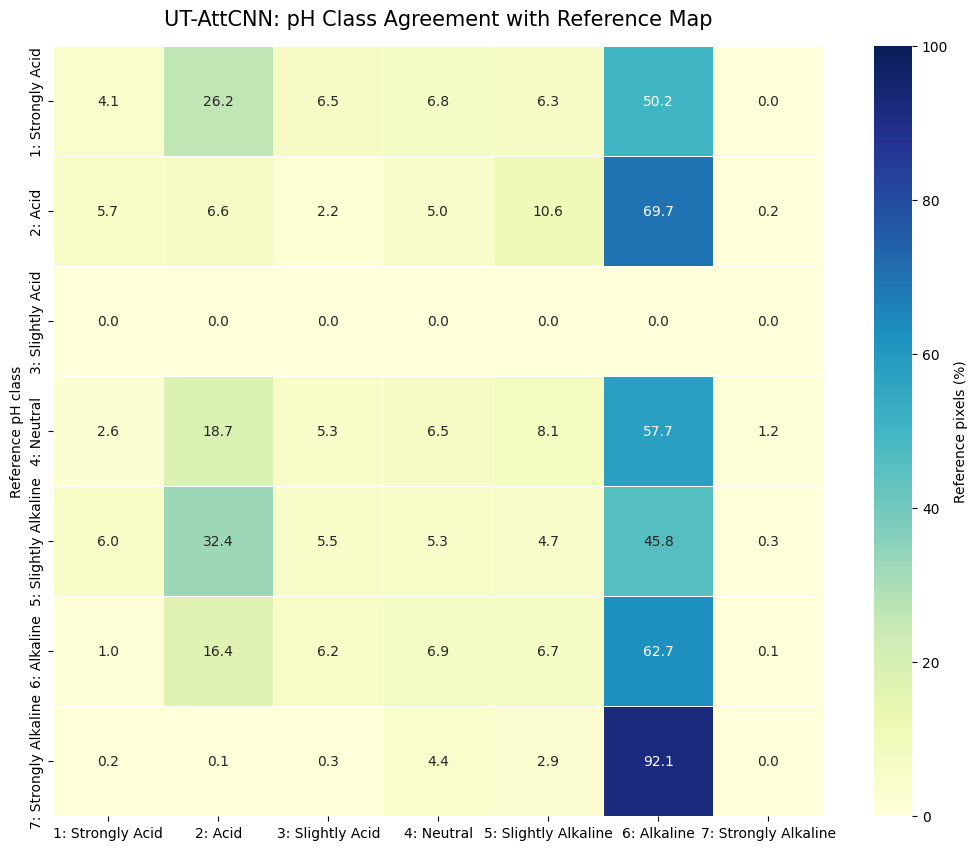

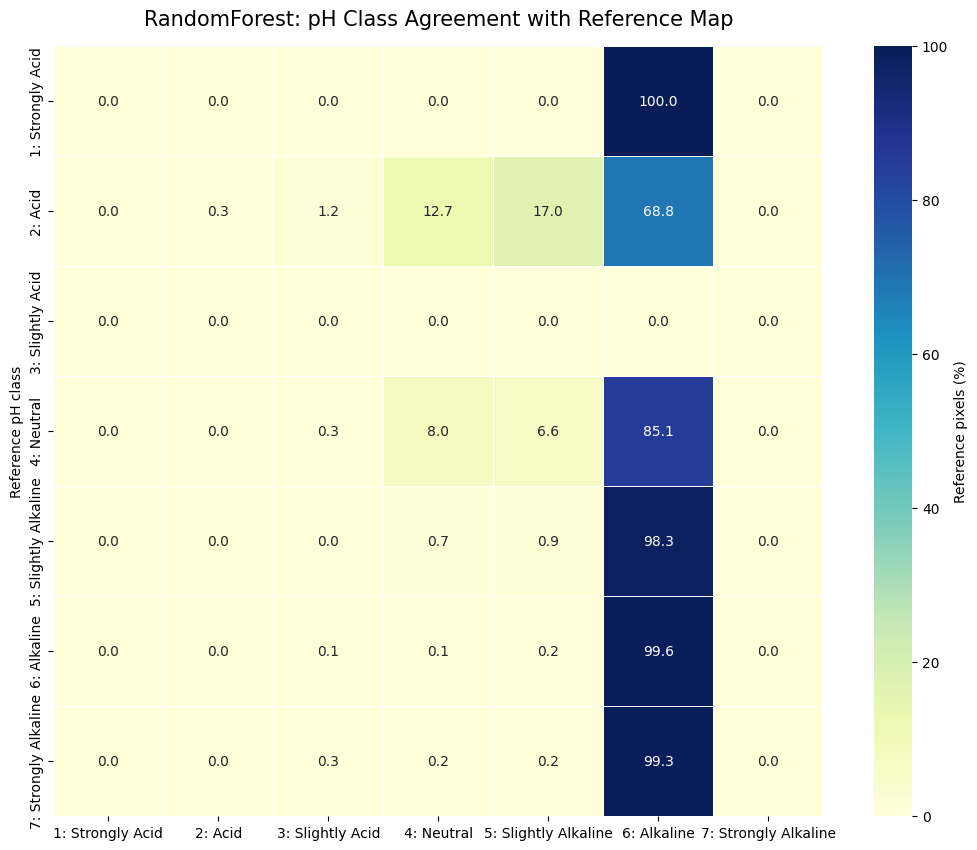

In [10]:

import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Use the same output folder as the previous script
output_dir = "external_data/"

class_names = [
    "Strongly Acid",
    "Acid",
    "Slightly Acid",
    "Neutral",
    "Slightly Alkaline",
    "Alkaline",
    "Strongly Alkaline"
]

# Consistent labels for all heatmaps
class_labels = [
    "1: Strongly Acid",
    "2: Acid",
    "3: Slightly Acid",
    "4: Neutral",
    "5: Slightly Alkaline",
    "6: Alkaline",
    "7: Strongly Alkaline"
]

# ---------------------------------------------------------
# 1. Confusion heatmaps: model 1 and model 2
# ---------------------------------------------------------
for model in ["UT-AttCNN", "RandomForest"]:

    csv_path = os.path.join(
        output_dir, f"confusion_percent_{model}.csv"
    )

    if not os.path.exists(csv_path):
        print(f"Missing file: {csv_path}")
        continue

    matrix = pd.read_csv(csv_path, index_col=0)

    # Ensure a consistent 7 x 7 layout
    matrix = matrix.iloc[:7, :7]
    matrix.index = class_labels[:len(matrix.index)]
    matrix.columns = class_labels[:len(matrix.columns)]

    plt.figure(figsize=(13, 10))

    sns.heatmap(
        matrix,
        annot=True,
        fmt=".1f",
        cmap="YlGnBu",
        vmin=0,
        vmax=100,
        linewidths=0.5,
        square=True,
        cbar_kws={"label": "Reference pixels (%)"}
    )

    plt.title(
        f"{model}: pH Class Agreement with Reference Map",
        fontsize=15,
        pad=15
    )
    plt.ylabel("Reference pH class")